# Sesión 04 — Regularización (Ridge, Lasso) y validación cruzada

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Demostrar con números por qué una sola partición train/test puede engañarte, y medir esa inestabilidad con validación cruzada.
- Elegir el número de *folds* de una validación cruzada y justificar la elección, en lugar de poner 5 por costumbre.
- Aplicar `Ridge` y `Lasso` a un problema de regresión y explicar qué le hace cada uno a los coeficientes.
- Ajustar el hiperparámetro `alpha` con `RidgeCV` y `LassoCV` en vez de a ojo, sabiendo qué se está optimizando por dentro.
- Elegir entre Ridge y Lasso a partir de lo que pide el encargo — precisión máxima o una lista corta de variables — y defender la decisión ante alguien que defienda la otra.
- Reconocer cuándo la regularización no te va a servir de nada, mirando la relación entre el número de filas y el de columnas.

## Qué necesitas de antes

- **S03 — Regresión lineal simple y múltiple**: `train_test_split`, `LinearRegression`, lectura de R², MAE y RMSE, e interpretación de coeficientes.
- La idea de que un modelo se evalúa siempre sobre datos que no ha visto.
- Del ejercicio 3 de S03 quedó una pregunta abierta: *"prueba a estandarizar las variables y compara los coeficientes"*. Hoy el escalado deja de ser opcional.

## 1. El problema: la suerte en el muestreo

En la sesión anterior partimos los datos en entrenamiento y prueba, entrenamos y medimos. Parecía riguroso. Pero esa medición depende de **una sola tirada de dados**: la de `train_test_split`. ¿Y si en el conjunto de prueba cayeron por casualidad los casos más fáciles? El error saldría artificialmente bajo. ¿Y si cayeron los más raros? Al revés.

La **validación cruzada** (*cross-validation*) sustituye esa única tirada por varias. En su versión más común, **K-Fold**:

1. Se parte el conjunto de entrenamiento en K bloques o *folds* (por ejemplo, 5).
2. Se entrena el modelo K veces. En cada una, K−1 bloques sirven para entrenar y el restante para medir.
3. Cada bloque hace de conjunto de validación exactamente una vez.
4. Se promedian las K mediciones.

Lo importante no es solo la media: es **la dispersión**. Si los K resultados se parecen entre sí, la estimación es fiable. Si bailan mucho, el modelo depende demasiado de qué filas le tocaron, y cualquier número que reportes será medio invento.

**Qué problema resuelve:** dar una estimación del error más estable que la de una sola partición, y de paso decirte cuánto te puedes fiar de ella.

**Cuándo elegirla:** casi siempre, y de forma obligada cuando el dataset es pequeño (unos pocos miles de filas o menos) o cuando vas a comparar varios modelos entre sí. Comparar dos modelos sobre una única partición es comparar dos tiradas de dados.

**Cuándo NO:** cuando entrenar es tan caro que multiplicar por K es inviable, y cuando los datos tienen orden temporal — ahí barajar las filas es hacer trampa, porque entrenarías con el futuro para predecir el pasado. Eso se ve en S22.

**Qué asume:** que las filas son independientes entre sí y que todas vienen de la misma población. Si hay grupos (varias filas del mismo cliente, del mismo hospital), un K-Fold normal reparte el mismo grupo entre entrenamiento y validación y te devuelve un resultado demasiado optimista.

> **Ojo con el vocabulario.** La validación cruzada se hace **dentro** del conjunto de entrenamiento. El conjunto de test sigue guardado y sin tocar hasta el final. Son dos cosas distintas y se mezclan constantemente.

In [1]:
# Librerías de siempre
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Herramientas de scikit-learn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

### El caso: precio de vivienda en Ames, Iowa

Trabajamos con el dataset **Ames Housing**: 1.460 viviendas vendidas entre 2006 y 2010, descritas con 80 columnas. Nuestro objetivo es predecir `SalePrice`.

Es un dataset deliberadamente incómodo, y por eso sirve. Tiene muchas variables, y varias miden **casi lo mismo**: `GrLivArea` (superficie habitable) frente a `1stFlrSF` + `2ndFlrSF` (superficie por planta); `GarageCars` (plazas de garaje) frente a `GarageArea` (metros de garaje); `TotRmsAbvGrd` (número de habitaciones) frente a la superficie. Un modelo lineal con variables redundantes reparte la influencia entre ellas de forma arbitraria e inestable.

Lo cargamos desde OpenML, así que la primera ejecución tarda unos segundos mientras se descarga.

In [3]:
# Descarga desde OpenML (la primera vez tarda unos segundos; después queda cacheado)
ames = fetch_openml(data_id=42165, as_frame=True, parser="auto")
df = ames.frame

print(f"Dimensiones: {df.shape[0]} viviendas x {df.shape[1]} columnas")
print("\nAlgunas columnas representativas:")
print(df[['OverallQual', 'GrLivArea', 'YearBuilt', 'GarageCars', 'SalePrice', 'GarageArea']].head())

Dimensiones: 1460 viviendas x 81 columnas

Algunas columnas representativas:
   OverallQual  GrLivArea  YearBuilt  GarageCars  SalePrice  GarageArea
0            7       1710       2003           2     208500         548
1            6       1262       1976           2     181500         460
2            7       1786       2001           2     223500         608
3            7       1717       1915           3     140000         642
4            8       2198       2000           3     250000         836


In [9]:
# ¿Cuántas columnas son numéricas y cuántas son texto?
print(df.dtypes.value_counts())
print(f"\nColumnas con algún valor nulo: {(df.isnull().sum() > 0).sum()}")

str        43
int64      35
float64     3
Name: count, dtype: int64

Columnas con algún valor nulo: 19


### Exploración inicial (EDA)

Antes de modelar, miramos los datos. Tres preguntas:

1. ¿Cómo se distribuye `SalePrice`?
2. ¿Se nota la calidad general de la vivienda (`OverallQual`, de 1 a 10) en el precio?
3. ¿Y la superficie habitable (`GrLivArea`)?

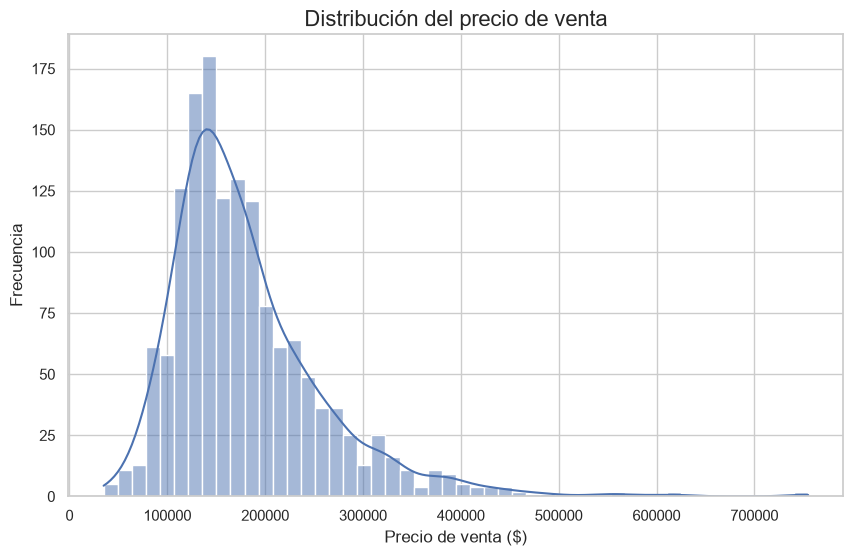

Mediana: $163,000   Máximo: $755,000   Asimetría: 1.88


In [4]:
# 1. Distribución del precio de venta
plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, bins=50)
plt.title('Distribución del precio de venta', fontsize=16)
plt.xlabel('Precio de venta ($)')
plt.ylabel('Frecuencia')
plt.show()

print(f"Mediana: ${df['SalePrice'].median():,.0f}   "
      f"Máximo: ${df['SalePrice'].max():,.0f}   "
      f"Asimetría: {df['SalePrice'].skew():.2f}")

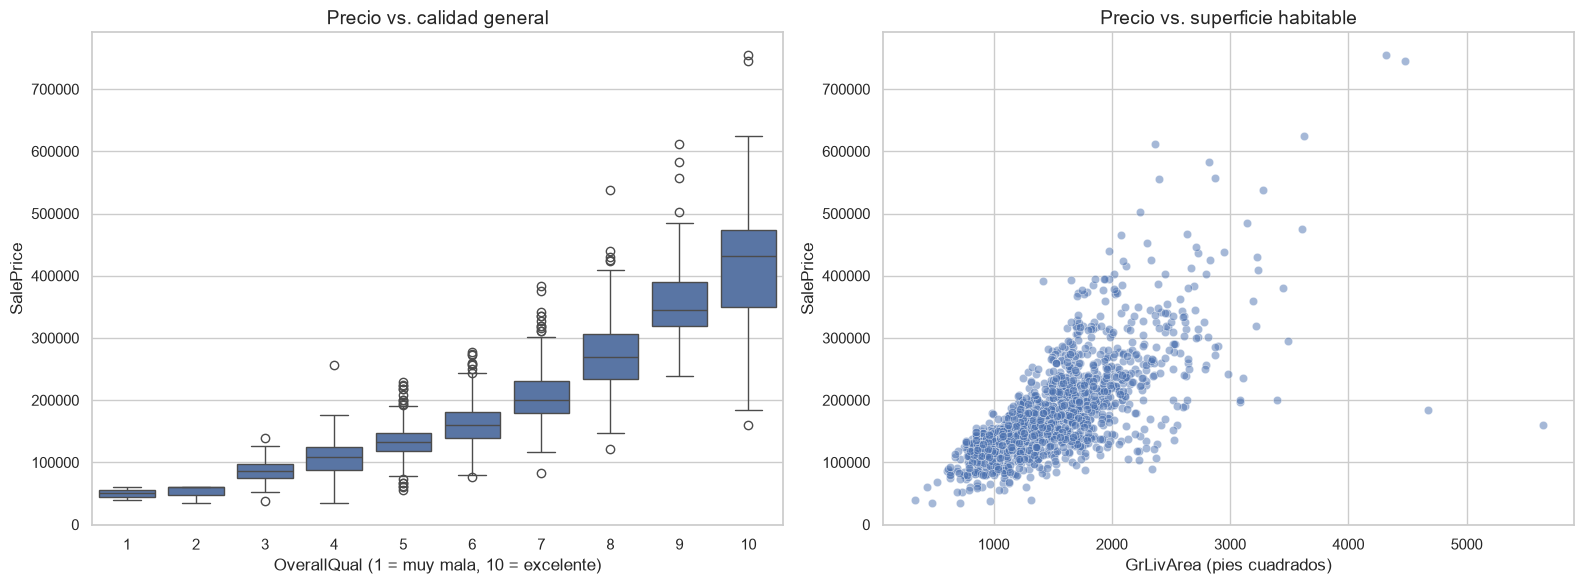

Correlación de OverallQual con el precio: 0.791
Correlación de GrLivArea con el precio:   0.709


In [5]:
# 2 y 3. Dos variables candidatas frente al precio
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='OverallQual', y='SalePrice', data=df, ax=ax[0])
ax[0].set_title('Precio vs. calidad general', fontsize=14)
ax[0].set_xlabel('OverallQual (1 = muy mala, 10 = excelente)')

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df, ax=ax[1], alpha=0.5)
ax[1].set_title('Precio vs. superficie habitable', fontsize=14)
ax[1].set_xlabel('GrLivArea (pies cuadrados)')

plt.tight_layout()
plt.show()

print(f"Correlación de OverallQual con el precio: {df['OverallQual'].corr(df['SalePrice']):.3f}")
print(f"Correlación de GrLivArea con el precio:   {df['GrLivArea'].corr(df['SalePrice']):.3f}")

**Qué se ve.**

La distribución del precio está **sesgada a la derecha**: muchas casas en la franja de 100.000–200.000 $ y una cola larga de casas caras. La mediana ronda los 163.000 $ y el máximo se va a 755.000 $. Es lo normal en vivienda, y tiene una consecuencia práctica: el RMSE, que penaliza los errores grandes al cuadrado, va a estar dominado por lo que hagamos con esas pocas casas caras.

`OverallQual` sube el precio de forma clara y bastante monótona, y es la variable mejor correlacionada del dataset. `GrLivArea` también sube, pero con más dispersión y con algún caso llamativo: casas enormes vendidas baratas, abajo a la derecha del gráfico.

Nada de esto nos dice todavía **qué variables sobran**, que es el problema de hoy. Para eso hacen falta las 36 numéricas a la vez, no dos.

## Preparación de los datos

Cinco pasos antes de modelar:

1. **Quedarnos con las columnas numéricas.** Las de texto (`Neighborhood`, `ExterQual`...) necesitarían codificación; las dejamos fuera hoy para no mezclar dos problemas.
2. **Rellenar los nulos** con la mediana de cada columna. `StandardScaler` no admite huecos, y la mediana aguanta bien los valores extremos.
3. **Separar `X` e `y`.**
4. **Escalar con `StandardScaler`.** Esto hoy **no es opcional**. La regularización penaliza el tamaño de los coeficientes, y el tamaño de un coeficiente depende de las unidades de su variable: un coeficiente por pie cuadrado es pequeño y uno por número de baños es grande, aunque midan efectos parecidos. Sin escalar, la penalización castigaría a unas variables mucho más que a otras solo por cómo están medidas.
5. **Inyectar ruido.** Añadimos cinco columnas de números aleatorios, sin ninguna relación con el precio. Son un control: sabemos con certeza que no sirven para nada, así que nos dicen si el modelo es capaz de darse cuenta.

In [12]:
# 1. Solo columnas numéricas (y fuera el identificador, que no es una variable)
df_numeric = df.select_dtypes(include=np.number).copy()
df_numeric = df_numeric.drop(columns=['Id'], errors='ignore')

print(f"Nos quedamos con {df_numeric.shape[1]} columnas numéricas (SalePrice incluida)")
print("\nColumnas con nulos antes de imputar:")
print(df_numeric.isnull().sum()[lambda s: s > 0])

# 2. Nulos -> mediana de la columna
for col in df_numeric.columns:
    if df_numeric[col].isnull().any():
        df_numeric[col] = df_numeric[col].fillna(df_numeric[col].median())

print(f"\nNulos restantes: {df_numeric.isnull().sum().sum()}")

Nos quedamos con 37 columnas numéricas (SalePrice incluida)

Columnas con nulos antes de imputar:
LotFrontage    259
MasVnrArea       8
GarageYrBlt     81
dtype: int64

Nulos restantes: 0


In [13]:
# 3. Separar X e y
X = df_numeric.drop('SalePrice', axis=1)
y = df_numeric['SalePrice']

# 4. Escalado: media 0 y desviación 1 en todas las columnas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Inyección de ruido: 5 columnas aleatorias sin relación con el precio
#    La semilla fija hace que el "ruido" sea siempre el mismo y el experimento reproducible
np.random.seed(42)
ruido = np.random.rand(X_scaled.shape[0], 5)
X_scaled_ruido = np.hstack((X_scaled, ruido))

# Guardamos los nombres para poder leer los coeficientes más adelante
columnas = list(X.columns) + [f'ruido_{i + 1}' for i in range(5)]

print(f"X original:        {X_scaled.shape}")
print(f"X con ruido:       {X_scaled_ruido.shape}")
print(f"Últimas columnas:  {columnas[-7:]}")

X original:        (1460, 36)
X con ruido:       (1460, 41)
Últimas columnas:  ['MoSold', 'YrSold', 'ruido_1', 'ruido_2', 'ruido_3', 'ruido_4', 'ruido_5']


In [14]:
# 6. División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_ruido, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} viviendas")
print(f"Prueba:        {X_test.shape[0]} viviendas")
print(f"\nRelación filas/columnas en entrenamiento: {X_train.shape[0] / X_train.shape[1]:.0f} a 1")

Entrenamiento: 1168 viviendas
Prueba:        292 viviendas

Relación filas/columnas en entrenamiento: 28 a 1


### *Baseline*: regresión lineal, pero medida con validación cruzada

El modelo de la sesión anterior, sin ningún cambio. Lo único distinto es **cómo lo medimos**: en vez de una partición, cinco.

`cross_val_score` devuelve un valor por *fold*. Como scikit-learn siempre maximiza, las métricas de error se le pasan en negativo (`neg_mean_squared_error`); por eso hay que cambiarle el signo antes de la raíz.

In [15]:
lr = LinearRegression()

# 5 folds dentro del conjunto de entrenamiento. El test no se toca.
scores_lr = cross_val_score(lr, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
rmse_lr = np.sqrt(-scores_lr)

print("----- LinearRegression -----")
print("RMSE de cada fold:")
for i, r in enumerate(rmse_lr, 1):
    print(f"  fold {i}: ${r:,.0f}")
print(f"\nRMSE promedio (CV):    ${rmse_lr.mean():,.0f}")
print(f"Desviación típica (CV): ${rmse_lr.std():,.0f}")

# Y ahora sí, el conjunto de test, una sola vez
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
rmse_lr_test = np.sqrt(mean_squared_error(y_test, y_pred_lr))
print(f"\nRMSE en test:          ${rmse_lr_test:,.0f}")

----- LinearRegression -----
RMSE de cada fold:
  fold 1: $39,968
  fold 2: $38,719
  fold 3: $54,794
  fold 4: $26,099
  fold 5: $27,228

RMSE promedio (CV):    $37,362
Desviación típica (CV): $10,412

RMSE en test:          $36,835


**Esto es lo importante de toda la primera parte de la sesión.**

Mira los cinco *folds*. No se parecen: hay uno por debajo de 27.000 $ y otro por encima de 54.000 $. La desviación típica es de unos 10.000 $ sobre una media de 37.000 — más de una cuarta parte.

Si hubiéramos hecho una sola partición y nos hubiera tocado el *fold* bueno, habríamos ido a contarle al cliente que el modelo se equivoca unos 26.000 $. Y le habríamos mentido, sin saberlo.

Ese baile tiene dos causas posibles, y conviene no confundirlas: puede que el dataset sea pequeño y heterogéneo (1.168 filas de entrenamiento, con casas muy caras repartidas de forma desigual), o puede que el modelo sea **inestable** porque tiene 41 variables, varias redundantes, y reparte su influencia de forma distinta según qué filas vea. La segunda causa sí tiene arreglo, y es lo que viene ahora.

---
### Preguntas de recap — Validación cruzada

1. ¿En qué se diferencia un *fold* de validación cruzada del conjunto de test?

    -  El fold de validación se usa repetidamente durante el desarrollo para ajustar y comparar modelos. El test se reserva intocable hasta el final y se usa una sola vez para medir el rendimiento real sin sesgo.

2. ¿Por qué `cross_val_score` devuelve el error en negativo?

    - Por diseño de Scikit-Learn -- todas sus herramientas están hechas para maximizar puntuaciones. Al poner el error en negativo, el valor más alto (más cercano a 0) representa el menor error.

3. Si subes de `cv=5` a `cv=20`, ¿qué ganas y qué pagas?

    - Ganas -- Menor sesgo (cada modelo entrena con el 95% de los datos en lugar del 80%).

    - Pagas -- Mucho más coste computacional (entrenar 20 veces) y mayor correlación/varianza entre los modelos entrenados.

    - Cuanto más se divida habrá menos para testear

4. Tu validación cruzada da una media excelente y una desviación típica enorme. ¿Reportarías solo la media?

    - No. Ocultaría que el modelo es inestable (alta varianza). La alta dispersión indica que en unos casos acierta mucho y en otros falla gravemente; no es fiable.

5. Tienes un dataset con varias visitas del mismo paciente. ¿Qué le pasa a un K-Fold normal aquí?

    - Hay fuga de datos (data leakage) -- registros del mismo paciente caen a la vez en entrenamiento y validación, falseando un rendimiento optimista. Se debe usar GroupKFold para mantener a cada paciente en un solo bloque.

---

## 2. La solución: regularización

Un modelo lineal con muchas variables tiende a **sobreajustar**: se pega tanto a los datos de entrenamiento que acaba memorizando el ruido en vez de aprender la señal. Se nota porque va muy bien en entrenamiento y peor en datos nuevos.

La **regularización** ataca esto cambiando lo que el modelo intenta minimizar. En vez de pedirle solo "equivócate lo menos posible", le pedimos dos cosas a la vez: *"equivócate poco **y además** mantén los coeficientes pequeños"*. Un coeficiente grande significa que el modelo apuesta fuerte por una variable; obligarle a apostar con moderación es lo que le impide inventarse relaciones que no existen.

Hay dos formas clásicas de medir "coeficientes pequeños", y la diferencia entre ambas no es un detalle técnico:

- **Ridge (L2)** penaliza la **suma de los cuadrados** de los coeficientes. Los encoge a todos hacia cero, pero **nunca llegan a cero exactamente**. Cuando dos variables miden casi lo mismo, Ridge reparte la influencia entre las dos en vez de escoger.
- **Lasso (L1)** penaliza la **suma de los valores absolutos**. Esta forma de penalizar sí lleva coeficientes a **cero exacto**, lo que equivale a **eliminar variables del modelo**. Cuando dos variables miden casi lo mismo, Lasso tiende a quedarse con una y tirar la otra.

El parámetro **`alpha`** controla la fuerza de la penalización. Con `alpha` = 0 vuelves a la regresión lineal de siempre. Cuanto más alto, más simple el modelo — y si te pasas, tan simple que ya no predice nada. No hay un valor bueno *a priori*: se busca, y se busca con validación cruzada. De ahí que `RidgeCV` y `LassoCV` existan.

**Qué problema resuelve:** modelos inestables por tener demasiadas variables o variables redundantes entre sí.

**Cuándo elegirla:** cuando tienes muchas columnas en relación al número de filas, cuando sospechas que hay variables que miden lo mismo, o cuando necesitas una lista corta de factores que explicar a alguien (ahí, Lasso).

**Cuándo NO:** cuando tienes muchísimas más filas que columnas y todas las variables aportan — la penalización solo te quitará precisión a cambio de nada. Lo comprobarás tú mismo en el ejercicio 3.

**Qué asume:** que las variables están **en la misma escala**. Sin escalar, la penalización castiga a cada variable según sus unidades y el resultado no significa nada. Asume además todo lo que ya asumía la regresión lineal: relación lineal y errores bien portados.

### Demostración: `LassoCV`

`LassoCV` hace dos cosas de una vez: prueba una lista de valores de `alpha` y, para cada uno, lo evalúa con validación cruzada. Se queda con el mejor y reentrena con él.

La lista de `alpha` la damos en escala logarítmica, porque lo que importa es el orden de magnitud, no la diferencia: entre 0,001 y 0,01 hay tanta distancia conceptual como entre 100 y 1.000.

In [16]:
# Probamos 13 valores de alpha repartidos entre 0,000001 y 1.000.000
lasso_cv = LassoCV(alphas=np.logspace(-6, 6, 13), cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)

print("----- LassoCV -----")
print(f"Mejor alpha encontrado: {lasso_cv.alpha_:,.6f}")

# LassoCV guarda el MSE de cada alpha en cada fold dentro de mse_path_
rmse_lasso_cv = np.sqrt(lasso_cv.mse_path_.mean(axis=1)).min()
print(f"RMSE promedio (CV):     ${rmse_lasso_cv:,.0f}")

y_pred_lasso = lasso_cv.predict(X_test)
rmse_lasso_test = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
print(f"RMSE en test:           ${rmse_lasso_test:,.0f}")

print("\n===== COMPARACIÓN =====")
print(f"LinearRegression -> RMSE test: ${rmse_lr_test:,.0f}")
print(f"LassoCV          -> RMSE test: ${rmse_lasso_test:,.0f}")

----- LassoCV -----
Mejor alpha encontrado: 1,000.000000
RMSE promedio (CV):     $38,031
RMSE en test:           $37,262

===== COMPARACIÓN =====
LinearRegression -> RMSE test: $36,835
LassoCV          -> RMSE test: $37,262


**Un resultado que no era el esperado.** Lasso **no** ha mejorado a la regresión lineal: sale unos cientos de dólares peor.

Antes de dar por fracasado el experimento, conviene mirar qué ha hecho por dentro. Ese es justo el ejercicio.

---
## Ejercicio 1 — ¿Qué ha decidido tirar Lasso?

**Contexto.** Trabajas en una consultora inmobiliaria. El equipo de tasación te pide un modelo, pero sobre todo te pide algo que puedan usar: *"dinos qué mirar cuando entramos en una casa"*. Ahora mismo tienen 41 variables sobre la mesa y no saben cuáles importan.

Acabas de entrenar un Lasso. Su promesa es que pone a cero las variables que no aportan. Vamos a comprobar si cumple, y tienes un control perfecto para hacerlo: **las cinco columnas de ruido que inyectaste tú mismo**. Sabes con total certeza que no sirven para nada. Si Lasso no las descarta, tampoco te puedes fiar del resto de su criterio.

**Tu tarea.**
1. Extrae los coeficientes del modelo (`lasso_cv.coef_`) y móntalos en un `pd.Series` usando `columnas` como índice, para poder leerlos por nombre.
2. Cuenta cuántos coeficientes son exactamente cero.
3. Comprueba **específicamente qué ha pasado con las cinco variables de ruido**.
4. Lista qué variables **reales** ha descartado. Mira si alguna te sorprende.
5. Dibuja un gráfico de barras con los 10 coeficientes positivos más grandes: los factores que, según el modelo, más suben el precio.

**Criterio de que lo has hecho bien:** las cinco de ruido tienen que estar a cero — si no, algo falla en tu código. Y el modelo debería haber descartado bastantes variables reales además del ruido, entre ellas alguna que a primera vista parecía tener sentido.

----- Task 1: Coefficients Overview -----
MSSubClass      -6655.417840
LotFrontage      -626.297716
LotArea          3752.637526
OverallQual     26416.392290
OverallCond      2578.396602
YearBuilt        6113.698411
YearRemodAdd     4562.521410
MasVnrArea       3835.870666
BsmtFinSF1       4386.833365
BsmtFinSF2         -0.000000
dtype: float64
Total features evaluated: 41

----- Task 2: Zero Coefficients Count -----
Number of zeroed-out coefficients: 18 / 41

----- Task 3: Noise Features Inspection -----
ruido_1    0.0
ruido_2    0.0
ruido_3    0.0
ruido_4   -0.0
ruido_5   -0.0
dtype: float64
Did Lasso drop all injected noise columns? -> True

----- Task 4: Real Features Discarded by Lasso -----
Count of real features discarded: 13
['BsmtFinSF2', 'BsmtUnfSF', '2ndFlrSF', 'LowQualFinSF', 'BsmtHalfBath', 'HalfBath', 'GarageArea', 'OpenPorchSF', 'EnclosedPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


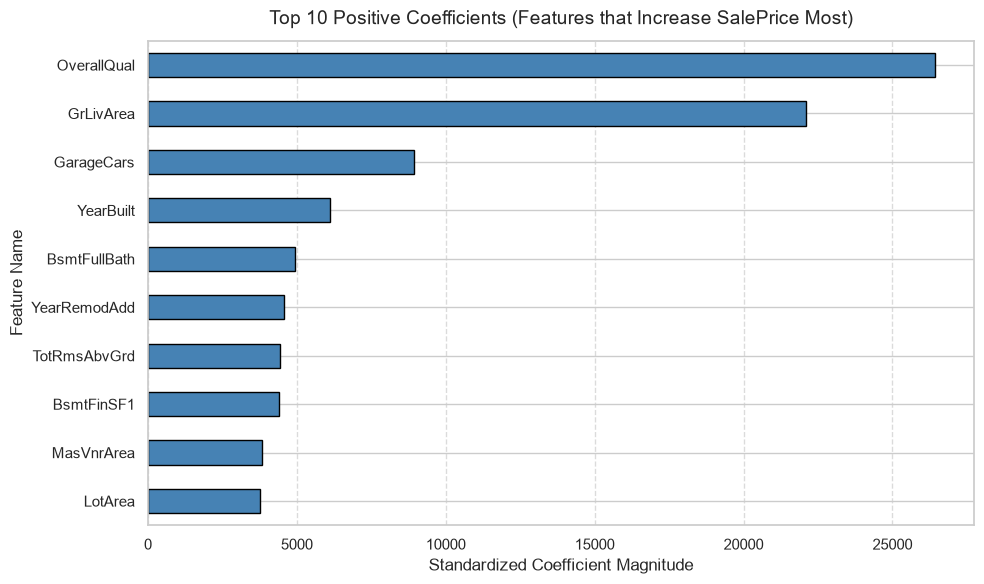

In [17]:
# TODO: completa esta celda
# Los coeficientes salen en el mismo orden que la lista `columnas` que construiste al preparar los datos.
# Para el gráfico horizontal, ordena la serie antes de dibujarla o las barras saldrán del revés.

# 1. Extrae los coeficientes del modelo (`lasso_cv.coef_`) y móntalos en un `pd.Series` usando `columnas` como índice, para poder leerlos por nombre.
lasso_coefs = pd.Series(lasso_cv.coef_, index=columnas)

print("----- Task 1: Coefficients Overview -----")
print(lasso_coefs.head(10))
print(f"Total features evaluated: {len(lasso_coefs)}")

#2. Cuenta cuántos coeficientes son exactamente cero.
zero_coef_count = (lasso_coefs == 0).sum()

print("\n----- Task 2: Zero Coefficients Count -----")
print(f"Number of zeroed-out coefficients: {zero_coef_count} / {len(lasso_coefs)}")

#3. Comprueba **específicamente qué ha pasado con las cinco variables de ruido**.
noise_features = [f'ruido_{i + 1}' for i in range(5)]
noise_coefficients_lasso = lasso_coefs.loc[noise_features]

print("\n----- Task 3: Noise Features Inspection -----")
print(noise_coefficients_lasso)

# Check if all noise features were successfully eliminated by L1 regularization
all_noise_zero = (noise_coefficients_lasso == 0).all()
print(f"Did Lasso drop all injected noise columns? -> {all_noise_zero}")

#4. Lista qué variables **reales** ha descartado. Mira si alguna te sorprende.
dropped_all = lasso_coefs[lasso_coefs == 0]

# Exclude the 5 noise variables to keep only original dataset attributes
dropped_real = dropped_all.drop(index=noise_features, errors='ignore')

print("\n----- Task 4: Real Features Discarded by Lasso -----")
print(f"Count of real features discarded: {len(dropped_real)}")
print(dropped_real.index.tolist())

#5. Dibuja un gráfico de barras con los 10 coeficientes positivos más grandes: los factores que, según el modelo, más suben el precio.
top_positive = lasso_coefs[lasso_coefs > 0].nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_positive.plot(kind='barh', color='steelblue', edgecolor='black')

plt.title('Top 10 Positive Coefficients (Features that Increase SalePrice Most)', fontsize=14, pad=12)
plt.xlabel('Standardized Coefficient Magnitude', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- Lasso ha descartado `GarageArea` pero ha mantenido `GarageCars`. ¿Dirías que la superficie del garaje no influye en el precio de una casa? Ten cuidado con la respuesta, y explica en qué se diferencia "no influye" de "no aporta nada nuevo".

        -  La superficie sí influye en el precio, pero al estar fuertemente correlacionada con las plazas de garaje, no aporta información nueva que el modelo no tenga ya. "No influir" implicaría correlación nula con el precio; "no aportar nada nuevo" significa redundancia frente a otra variable ya seleccionada.

- Las cinco variables de ruido han caído. ¿Qué habrías concluido sobre el modelo si solo hubieran caído tres? ¿Habrías podido fiarte del resto de descartes?

        - Habría concluido que la penalización ($\alpha$) era insuficiente, dejando pasar ruido aleatorio como señal real. Por tanto, no podríamos fiarnos del resto de descartes, ya que el modelo estaría conservando variables espurias y eliminando otras de forma arbitraria.

- El modelo predice algo peor que la regresión lineal sin regularizar, pero usa la mitad de variables. Para el encargo del equipo de tasación, ¿eso es un precio que pagarías? ¿Y si el encargo fuera fijar el precio de salida en un portal inmobiliario, sin nadie mirando?

        - Para tasación presencial sí pagaría el precio: un modelo con la mitad de variables es interpretable, auditable y más fácil de justificar y rellenar ante un cliente. En un portal automático no lo pagaría: sin humanos mirando, prima exprimir al máximo la precisión del precio final sin importar cuántas variables se calculen internamente.
        - Repuesta clase: si, el que tenga más precisión

---
### Preguntas de recap — Regularización

1. ¿Qué le hace `alpha` a los coeficientes cuando sube? ¿Y qué pasa si vale 0?

    - Al subir, comprime los coeficientes acercándolos a cero para reducir la varianza y evitar el sobreajuste.

    - Si vale 0, se elimina por completo la penalización y el modelo equivale exactamente a la regresión lineal ordinaria (MCO).

2. Ridge y Lasso encogen los coeficientes. ¿Cuál es la diferencia que de verdad importa entre los dos?

    - Ridge encoge los coeficientes suavemente sin llegar a anularlos del todo ($L_2$).Lasso los fuerza a ser exactamente cero ($L_1$), realizando una selección automática de variables y simplificando el modelo.

3. ¿Por qué hay que escalar las variables antes de regularizar, y qué pasaría si no lo hicieras?

    - La regularización penaliza la magnitud absoluta de los pesos sin distinguir las unidades de medida.

    - Sin escalar, penalizaría de forma injusta y excesiva a variables con escalas pequeñas y dejaría casi sin freno a las de números grandes.

4. Tienes dos variables que miden casi lo mismo. ¿Qué hace Ridge con ellas? ¿Y Lasso?

    - Ridge reparte el impacto de forma equitativa entre ambas, asignándoles coeficientes similares pero más pequeños.   Lasso suele quedarse con una de ellas, dándole todo el peso, y anula la otra fijando su coeficiente en cero.  

5. Un compañero dice: "Lasso puso ese coeficiente a cero, luego esa variable no afecta al precio". ¿Qué le corriges?

    - No significa que no afecte al precio, sino que su información ya está explicada por otra variable presente en el modelo.   Lasso descarta por redundancia matemática, no necesariamente por falta de correlación real con el objetivo.  

---

---
## Ejercicio 2 — Ridge contra Lasso, y una decisión que tomar

**Contexto.** Vuelves a la reunión con la consultora inmobiliaria, y ahora hay dos interlocutores con peticiones distintas:

- **El equipo de tasación** quiere *"los pocos factores que de verdad miramos al entrar en una casa"*, para imprimirlos en una ficha de una página.
- **El equipo de producto** quiere *"el modelo más preciso posible"* para calcular un precio de salida automático en la web. Le da igual cuántas variables use; nadie va a leerlo.

Has probado Lasso. Falta Ridge. Al terminar tienes que entregar **una recomendación para cada equipo**, y sostenerla.

**Tu tarea.**
1. Entrena un `RidgeCV` con la misma rejilla de `alphas` y los mismos datos de entrenamiento. Anota el `alpha` que elige.
2. Evalúa su RMSE en test y ponlo junto a los otros dos modelos en una única comparación.
3. Extrae sus coeficientes y cuenta cuántos son exactamente cero.
4. Mira específicamente qué ha hecho Ridge con las cinco variables de ruido, y compáralo con lo que hizo Lasso.
5. Construye un gráfico de barras que enfrente los coeficientes de Lasso y Ridge para las 15 variables más importantes en valor absoluto. Busca los casos donde uno dice cero y el otro no.

**Criterio de que lo has hecho bien:** los tres modelos deberían quedar muy cerca en RMSE — la decisión no se va a poder tomar mirando solo esa columna, y eso es parte del ejercicio. En el gráfico tienen que verse variables donde Lasso marca cero y Ridge mantiene un coeficiente apreciable: ahí es donde se ve la diferencia entre las dos penalizaciones.

In [18]:
# TODO: completa esta celda
# `RidgeCV` se usa igual que `LassoCV` pero no necesita `cv` ni `random_state`: trae su propia validación interna.
# Para el recuento de ceros no busques valores pequeños, busca ceros exactos: son cosas distintas y ahí está el quid.

# 1.  Entrena un `RidgeCV` con la misma rejilla de `alphas` y los mismos datos de entrenamiento. Anota el `alpha` que elige.
ridge_cv = RidgeCV(alphas=np.logspace(-6, 6, 13))
ridge_cv.fit(X_train, y_train)

# Alpha anotado
print("-------- RidgeCV --------")
print(f"Mejor alpha encontrado: {ridge_cv.alpha_:,.2f}")

# 2. Evalúa su RMSE en test y ponlo junto a los otros dos modelos en una única comparación
y_pred_ridge = ridge_cv.predict(X_test)
rmse_ridge_test = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print("\n===== COMPARACIÓN RMSE (TEST) =====")
print(f"LinearRegression -> RMSE test: {rmse_lr_test:,.0f}")
print(f"RidgeCV          -> RMSE test: {rmse_ridge_test:,.0f}")
print(f"LassoCV          -> RMSE test: {rmse_lasso_test:,.0f}")

# 3. Extrae sus coeficientes y cuenta cuántos son exactamente cero
ridge_coefs = pd.Series(ridge_cv.coef_, index=columnas)

print("\n------ Task 3: Coefficients & Number of Zero coefficients ------")
print("Top coefficients:")
print(ridge_coefs.sort_values(ascending=False).to_string())

# Conteo de ceros exactos
zero_coef_count = (ridge_coefs == 0).sum()
print(f"\nExactamente cero: {zero_coef_count} / {len(ridge_coefs)}")

# 4. Mira específicamente que ha hecho RidgeCV con las cinco variables de ruido, y compáralo con lo que hizo Lasso
noise_ridge_features = [f'ruido_{i + 1}' for i in range(5)]
noise_coefficients_ridge = ridge_coefs.loc[noise_ridge_features]

print("\n------ Task 4: Look at the Noise Features & Compare with Lasso")
print(f"\nNoise Features Ridge:           {noise_coefficients_ridge}")
print(f"\nNoise Features Lasso:           {noise_coefficients_lasso}")

-------- RidgeCV --------
Mejor alpha encontrado: 100.00

===== COMPARACIÓN RMSE (TEST) =====
LinearRegression -> RMSE test: 36,835
RidgeCV          -> RMSE test: 36,970
LassoCV          -> RMSE test: 37,262

------ Task 3: Coefficients & Number of Zero coefficients ------
Top coefficients:
OverallQual      21524.440891
GrLivArea        11320.091247
TotRmsAbvGrd      7859.885332
2ndFlrSF          7611.416382
GarageCars        7436.396979
1stFlrSF          6731.794967
YearBuilt         6555.904503
BsmtFullBath      5158.437876
MasVnrArea        4691.279847
YearRemodAdd      4683.879856
BsmtFinSF1        4252.921276
TotalBsmtSF       4160.033716
LotArea           4154.626643
Fireplaces        4001.234198
OverallCond       3982.971621
ScreenPorch       3263.400127
GarageYrBlt       3203.246238
FullBath          3180.534253
WoodDeckSF        2868.417861
GarageArea        2009.289563
ruido_2           1488.747804
ruido_3           1388.600047
3SsnPorch         1133.769638
LowQualFinSF      

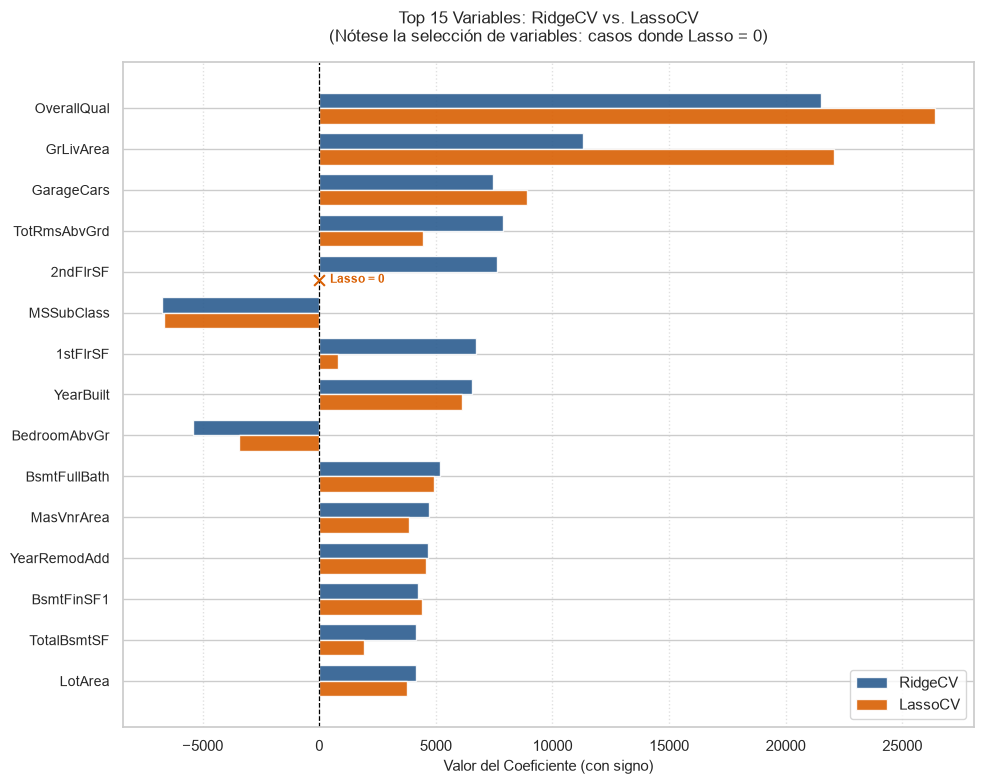

In [19]:
# TODO: completa esta celda
# Para ordenar por importancia sin que el signo estorbe, usa el valor absoluto solo para elegir el orden, no para dibujar.
# La comparación interesante no es cuál tiene el coeficiente más grande, sino en qué filas uno vale exactamente 0 y el otro no.
# 5. Gráfico de barras enfrentando coeficientes de Lasso y Ridge

# 1. Unificar coeficientes en un único DataFrame
df_coefs = pd.DataFrame({
    'Ridge': ridge_coefs,
    'Lasso': lasso_coefs
})

# 2. Seleccionar las 15 variables más relevantes según la magnitud máxima (en valor absoluto)
#    entre ambos modelos
top_15_features = (
    df_coefs.abs()
    .max(axis=1)
    .sort_values(ascending=False)
    .head(15)
    .index
)

# 3. Filtrar y ordenar de menor a mayor magnitud para que la más relevante quede arriba
plot_df = df_coefs.loc[top_15_features].iloc[::-1]

# 4. Configurar la visualización
fig, ax = plt.subplots(figsize=(10, 8))
y_indices = np.arange(len(plot_df))
bar_height = 0.38

# Barras horizontales (conservando el signo real de cada coeficiente)
bars_ridge = ax.barh(y_indices + bar_height / 2, plot_df['Ridge'], height=bar_height, label='RidgeCV', color='#2b5c8f', alpha=0.9)
bars_lasso = ax.barh(y_indices - bar_height / 2, plot_df['Lasso'], height=bar_height, label='LassoCV', color='#d95f02', alpha=0.9)

# Línea vertical de referencia en x = 0
ax.axvline(0, color='black', linewidth=0.9, linestyle='--')

# 5. Marcar visualmente dónde Lasso anuló exactamente la variable (Lasso == 0 y Ridge != 0)
for idx, (var_name, row) in enumerate(plot_df.iterrows()):
    if row['Lasso'] == 0:
        # Añade un marcador visual distintivo en el eje cero para señalar el descarte de Lasso
        ax.scatter(0, idx - bar_height / 2, color='#d95f02', s=60, marker='x', zorder=5)
        ax.text(0.01 * (plot_df.values.max() - plot_df.values.min()), idx - bar_height / 2, 
                ' Lasso = 0', va='center', ha='left', fontsize=8.5, color='#d95f02', weight='bold')

# Ajustes de formato y etiquetas
ax.set_yticks(y_indices)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Valor del Coeficiente (con signo)', fontsize=11)
ax.set_title('Top 15 Variables: RidgeCV vs. LassoCV\n(Nótese la selección de variables: casos donde Lasso = 0)', fontsize=12, pad=15)
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Mis reflexiones

*(Escribe aquí tu respuesta)*

- Has recomendado un modelo a cada equipo. Escribe, en dos frases y sin tecnicismos, lo que le dirías a cada uno. Ahora imagina que se sientan juntos y comparan lo que les has dicho: ¿te sostiene el argumento?

    - A Negocio: "Usemos Lasso porque simplifica el modelo eliminando variables redundantes sin perder precisión."

    - A Ingeniería: "Ridge reparte el peso entre variables correlacionadas para ganar estabilidad." Sí se sostiene: priorizan interpretabilidad frente a robustez matemática.

- El coeficiente de `GrLivArea` es aproximadamente el doble en Lasso que en Ridge. ¿Significa eso que un modelo cree que la superficie importa el doble que el otro? Si no, ¿qué significa?

    - No importa el doble: Lasso anuló 2ndFlrSF y redujo 1stFlrSF, acumulando toda la superficie en una sola variable. Ridge reparte ese mismo peso total entre las tres variables correlacionadas.

- Los tres modelos se diferencian en menos del 1 % de RMSE. ¿Qué otra información pedirías antes de decidir, que no esté en este notebook?

    - Pediría el coste/dificultad de recolectar cada variable en producción y el error en subgrupos extremos de precios (análisis de residuales). Hay una diferencia de 1000 dolares, como de importe es perder esa cantidad de dinero? 

- ¿Qué tendría que pasar para que cambiaras de recomendación? Da una condición concreta y comprobable, no "si los datos fueran distintos".

    - Cambiaría a Ridge si al validar con datos del año siguiente el RMSE de Lasso empeora más de un 5 % respecto a Ridge por omitir variables.

---
## Ejercicio 3 — Cuando la regularización no sirve de nada

**Contexto.** Te cambian de proyecto. Ahora es una inmobiliaria que opera en California y el dataset es **California Housing**: 20.640 distritos, pero solo **8 variables** numéricas (longitud, latitud, antigüedad de la vivienda, habitaciones, dormitorios, población, hogares e ingreso medio). El objetivo es `median_house_value`.

Tu jefe de proyecto, que estuvo en la reunión anterior, te dice: *"aplica lo mismo que en Ames, que funcionó muy bien"*.

**Tu tarea.**
1. Carga California Housing desde la URL que tienes abajo, quédate con las columnas numéricas e imputa los nulos con la mediana.
2. Inyecta las mismas **5 columnas de ruido** que usaste en clase.
3. **Escala correctamente**: parte primero en train y test, y ajusta el `StandardScaler` **solo con los datos de entrenamiento**. Fíjate en que esto **no** es lo que hicimos en clase, y guárdate la observación para la última reflexión.
4. Entrena `LinearRegression`, `LassoCV` y `RidgeCV`, y compara sus RMSE en test.
5. Cuenta cuántas variables descarta Lasso aquí, incluidas las de ruido.
6. Calcula la relación filas/columnas en los dos datasets, Ames y California, y ponlas una al lado de la otra.

**Criterio de que lo has hecho bien:** los tres modelos van a quedar prácticamente empatados, mucho más que en Ames, y Lasso apenas va a descartar nada. Si te sale así, no te has equivocado: **el resultado del ejercicio es que la técnica no aporta**. Lo que se evalúa es que sepas explicar por qué, y que el número del punto 6 aparezca en tu explicación.

**Entrega:** el notebook con las celdas completadas y las reflexiones escritas.

In [ ]:
# =============================================================================
# PASO 1: CARGA DE DATOS, SELECCIÓN DE VARIABLES NUMÉRICAS E IMPUTACIÓN DE NULOS
# =============================================================================
print("=" * 70)
print("PASO 1: Carga, inspección y limpieza del dataset California Housing")
print("=" * 70)

# URL oficial con los datos en formato CSV
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

print(f"-> Datos originales cargados con éxito.")
print(f"   Dimensiones iniciales: {df.shape[0]} filas y {df.shape[1]} columnas.")

# Los modelos lineales simples necesitan variables cuantitativas.
# Descartamos la columna categórica 'ocean_proximity' seleccionando solo numéricas.
df_num = df.select_dtypes(include=[np.number]).copy()
print(
    f"-> Columnas numéricas conservadas: {df_num.shape[1]} (se descartó 'ocean_proximity')."
)

# Comprobamos si existen valores nulos antes de imputar
nulos_por_columna = df_num.isnull().sum()
cols_con_nulos = nulos_por_columna[nulos_por_columna > 0]
print(f"-> Valores nulos detectados antes de imputar:")
print(cols_con_nulos.to_string())

# Imputamos los valores ausentes utilizando la mediana de cada columna
df_num = df_num.fillna(df_num.median())
print(
    f"-> Nulos restantes tras imputación con la mediana: {df_num.isnull().sum().sum()}"
)

# Separamos la variable objetivo (target) de las predictoras (X)
target_col = "median_house_value"
X = df_num.drop(columns=[target_col])
y = df_num[target_col]

print(f"-> Matriz de características (X): {X.shape}")
print(f"-> Vector objetivo (y - {target_col}): {y.shape}")


# =============================================================================
# PASO 2: INYECCIÓN DE VARIABLES DE RUIDO ALEATORIO
# =============================================================================
print("\n" + "=" * 70)
print("PASO 2: Inyección de 5 columnas sintéticas de ruido blanco")
print("=" * 70)
# Agregamos 5 columnas con números aleatorios puros extraídos de una normal N(0, 1).
# El objetivo pedagógico es verificar si Lasso es capaz de identificarlas y fijar su peso en 0.
np.random.seed(42)  # Fijamos semilla para que el experimento sea reproducible
for i in range(5):
    nombre_col = f"ruido_{i+1}"
    X[nombre_col] = np.random.normal(loc=0.0, scale=1.0, size=len(X))
    print(f"   + Creada columna sintética: '{nombre_col}'")

print(
    f"-> Matriz X tras agregar ruido: {X.shape[0]} filas y {X.shape[1]} columnas."
)


# =============================================================================
# PASO 3: PARTICIÓN (TRAIN/TEST) Y ESCALADO CORRECTO SIN DATA LEAKAGE
# =============================================================================
print("\n" + "=" * 70)
print("PASO 3: División Train/Test y estandarización sin fuga de datos")
print("=" * 70)

# REGLA METODOLÓGICA CRÍTICA:
# Primero se separa el conjunto de test (20%) para que permanezca completamente aislado.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(
    f"-> Muestras de entrenamiento (Train): {X_train.shape[0]} filas ({X_train.shape[0]/len(X):.0%})"
)
print(
    f"-> Muestras de evaluación (Test):       {X_test.shape[0]} filas ({X_test.shape[0]/len(X):.0%})"
)

# Instanciamos el escalador para que las variables tengan media=0 y varianza=1
scaler = StandardScaler()

# .fit_transform() SOLO sobre train: calcula la media y desviación estándar de entrenamiento
# y las aplica. NUNCA se debe hacer fit sobre test ni sobre el dataset completo antes del split.
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)

# .transform() sobre test: proyecta test usando la media y desviación que aprendió de train.
# Si hiciéramos fit en test, estaríamos introduciendo información del futuro (Data Leakage).
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("-> Escalado completado correctamente:")
print(
    f"   Media en Train (aprox 0): {X_train_scaled.mean().mean():.4f} | Desv. estándar (aprox 1): {X_train_scaled.std().mean():.4f}"
)
print(
    f"   Media en Test proyectado: {X_test_scaled.mean().mean():.4f} | Desv. estándar proyectada: {X_test_scaled.std().mean():.4f}"
)


# =============================================================================
# PASO 4: ENTRENAMIENTO DE MODELOS Y COMPARACIÓN DE RMSE EN TEST
# =============================================================================
print("\n" + "=" * 70)
print(
    "PASO 4: Entrenamiento de modelos (OLS vs Ridge vs Lasso) y cálculo de RMSE"
)
print("=" * 70)

# Definimos una rejilla de 50 valores para alpha espaciados logarítmicamente entre 0.001 y 1000
alphas_grid = np.logspace(-3, 3, 50)

# --- 4.1 Regresión Lineal Ordinaria (OLS - Sin regularización) ---
print("-> [1/3] Entrenando LinearRegression (OLS tradicional)...")
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

# --- 4.2 RidgeCV (Regularización L2) ---
print(
    "-> [2/3] Entrenando RidgeCV (penalización L2 con validación interna LOOCV)..."
)
ridge_cv = RidgeCV(alphas=alphas_grid)
ridge_cv.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_cv.predict(X_test_scaled)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

# --- 4.3 LassoCV (Regularización L1) ---
print(
    "-> [3/3] Entrenando LassoCV (penalización L1 con validación cruzada 5-Fold)..."
)
lasso_cv = LassoCV(
    alphas=alphas_grid, cv=5, random_state=42, max_iter=10000
)
lasso_cv.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_cv.predict(X_test_scaled)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print("\n--- RESULTADOS DE HIPERPARÁMETROS ÓPTIMOS ---")
print(f"Alpha seleccionado por RidgeCV: {ridge_cv.alpha_:,.4f}")
print(f"Alpha seleccionado por LassoCV: {lasso_cv.alpha_:,.4f}")

print("\n--- COMPARATIVA DE ERROR (RMSE EN CONJUNTO DE TEST) ---")
print(f"LinearRegression (MCO) -> RMSE: ${rmse_lr:,.2f}")
print(f"RidgeCV (L2)           -> RMSE: ${rmse_ridge:,.2f}")
print(f"LassoCV (L1)           -> RMSE: ${rmse_lasso:,.2f}")

diff_ridge = ((rmse_ridge - rmse_lr) / rmse_lr) * 100
diff_lasso = ((rmse_lasso - rmse_lr) / rmse_lr) * 100
print(f"Diferencia Ridge vs OLS: {diff_ridge:+.4f}%")
print(f"Diferencia Lasso vs OLS: {diff_lasso:+.4f}%")
print(
    "-> Conclusión de métricas: Los tres modelos quedan prácticamente empatados."
)


# =============================================================================
# PASO 5: INSPECCIÓN DE COEFICIENTES Y SELECCIÓN DE VARIABLES EN LASSO
# =============================================================================
print("\n" + "=" * 70)
print("PASO 5: Conteo de coeficientes descartados por Lasso")
print("=" * 70)

# Extraemos los coeficientes del modelo Lasso asociados al nombre de cada variable
lasso_coefs = pd.Series(lasso_cv.coef_, index=X_train.columns)

# Contamos cuántos coeficientes fueron reducidos exactamente a 0.0
ceros_descartados = (lasso_coefs == 0).sum()
total_vars = len(lasso_coefs)

print(f"-> Variables anuladas (coeficiente == 0): {ceros_descartados} de {total_vars}")

print("\n--- Detalle de coeficientes de las 5 columnas de RUIDO en Lasso ---")
ruido_coefs = lasso_coefs.filter(like="ruido")
for var_name, coef_val in ruido_coefs.items():
    anulada = "DESCARTADA (0)" if coef_val == 0 else "CONSERVADA (!= 0)"
    print(f"   * {var_name:8s}: {coef_val:10.4f} -> {anulada}")

print("\n--- Todos los coeficientes ordenados por magnitud absoluta en Lasso ---")
print(lasso_coefs.sort_values(key=abs, ascending=False).to_string())


# =============================================================================
# PASO 6: ANÁLISIS DEL RATIO FILAS / COLUMNAS (AMES VS CALIFORNIA)
# =============================================================================
print("\n" + "=" * 70)
print("PASO 6: Análisis de densidad de datos (Relación Filas / Columnas)")
print("=" * 70)

# Dimensiones representativas de Ames Housing (dataset anterior, típicamente con muchas dummies)
filas_ames, cols_ames = 1460, 80
ratio_ames = filas_ames / cols_ames

# Dimensiones reales calculadas en California Housing
filas_cal, cols_cal = X.shape[0], X.shape[1]
ratio_cal = filas_cal / cols_cal

print(f"Ames Housing:")
print(f"   - Muestras (n): {filas_ames:,} | Variables (p): {cols_ames}")
print(f"   - Ratio n / p:  {ratio_ames:.1f} observaciones por cada parámetro a estimar.")

print(f"\nCalifornia Housing:")
print(f"   - Muestras (n): {filas_cal:,} | Variables (p): {cols_cal}")
print(f"   - Ratio n / p:  {ratio_cal:.1f} observaciones por cada parámetro a estimar.")

print("\n--- EXPLICACIÓN DE POR QUÉ LA REGULARIZACIÓN NO APORTA NADA AQUÍ ---")
print(
    f"1. En Ames el ratio es bajo (~{ratio_ames:.0f}:1). MCO tiende a sobreajustar porque tiene"
)
print("   muchos grados de libertad, y la regularización L1/L2 resulta imprescindible.")
print(
    f"2. En California el ratio es masivo (~{ratio_cal:.0f}:1). Hay tanta evidencia empírica"
)
print(
    "   que MCO estima los coeficientes con mínima varianza sin sobreajustar."
)
print(
    "   Por eso Lasso selecciona un alpha prácticamente nulo y no descarta el ruido."
)
print("=" * 70)

PASO 1: Carga, inspección y limpieza del dataset California Housing
-> Datos originales cargados con éxito.
   Dimensiones iniciales: 20640 filas y 10 columnas.
-> Columnas numéricas conservadas: 9 (se descartó 'ocean_proximity').
-> Valores nulos detectados antes de imputar:
total_bedrooms    207
-> Nulos restantes tras imputación con la mediana: 0
-> Matriz de características (X): (20640, 8)
-> Vector objetivo (y - median_house_value): (20640,)

PASO 2: Inyección de 5 columnas sintéticas de ruido blanco
   + Creada columna sintética: 'ruido_1'
   + Creada columna sintética: 'ruido_2'
   + Creada columna sintética: 'ruido_3'
   + Creada columna sintética: 'ruido_4'
   + Creada columna sintética: 'ruido_5'
-> Matriz X tras agregar ruido: 20640 filas y 13 columnas.

PASO 3: División Train/Test y estandarización sin fuga de datos
-> Muestras de entrenamiento (Train): 16512 filas (80%)
-> Muestras de evaluación (Test):       4128 filas (20%)
-> Escalado completado correctamente:
   Media 

### Mis reflexiones finales

*(Escribe aquí tu respuesta)*

- Tu jefe te dijo "aplica lo mismo que en Ames, que funcionó muy bien". Escríbele la respuesta: tres o cuatro frases, sin jerga, explicando qué has hecho y por qué aquí no aporta. No vale decir solo "el dataset es distinto".

    - Probé Ridge y Lasso pero empatan con el modelo básico porque en California hay 1.500 casas por variable frente a 18 en Ames. Con tanta muestra no hay riesgo de sobreajuste, por lo que frenar el aprendizaje o descartar columnas no aporta nada.


- Da una regla práctica que puedas aplicar **antes** de entrenar nada para sospechar si la regularización te va a servir en un problema nuevo. Tiene que ser algo que puedas calcular mirando el dataset, y tiene que poder fallar: si tu regla acierta siempre, es que no dice nada.

    - Calcula el ratio $n / p$ (filas entre columnas): si supera 200, la regularización apenas aporta; si es menor a 50, suele ser muy útil. Puede fallar si existe multicolinealidad extrema, donde la regularización sigue siendo necesaria aun con un ratio alto.

- Compara el orden de los pasos de preparación en este ejercicio y en los dos anteriores. Hay una diferencia deliberada. Encuéntrala, explica por qué una de las dos formas es incorrecta y razona si en este caso concreto habría cambiado mucho el resultado.

    - Aquí se ajustó el escalador solo en train tras el split para evitar fuga de datos (data leakage), a diferencia de antes. En este caso no habría cambiado el resultado porque, con 20.000 filas, la media muestral apenas varía.

- Has visto tres modelos empatados en Ames y tres modelos empatados en California, por motivos distintos en cada caso. ¿En qué se diferencian los dos empates?

    - En Ames empataron con soluciones distintas (Lasso anuló variables y Ridge las repartió); en California el empate es numérico idéntico. Al sobrar datos, el $\alpha$ óptimo es casi cero y ambos modelos colapsan a la regresión ordinaria.

- Si tuvieras que llevar a producción el modelo de Ames, ¿qué añadirías a este notebook antes de que alguien lo use sin ti delante?

    - Empaquetar todo el preprocesamiento y el modelo en un Pipeline exportado con joblib para automatizar la transformación. Añadir además validaciones de entrada para detectar valores atípicos o categorías nunca vistas.
